# Análise Exploratória de Dados (EDA) — LIAR-BR

**RES IA ELD UNB — Turma 2 | Grupo 5 |**  
**Challenge 1 — FOMO**

## 1. Contextualização

Esta Análise Exploratória de Dados (EDA) tem como objetivo investigar as principais características estruturais, textuais e de qualidade do conjunto de dados LIAR-BR, um dos datasets selecionados pelo grupo durante a etapa de levantamento e avaliação de conjuntos de dados relacionados à desinformação.

O LIAR-BR é uma versão em português brasileiro derivada do dataset LIAR e contém declarações curtas associadas a diferentes níveis de veracidade, além de metadados relacionados às declarações e aos seus emissores.

A realização da EDA permite compreender como os dados estão organizados, identificar possíveis problemas de qualidade, verificar a distribuição das classes, analisar características dos textos e investigar padrões que possam influenciar etapas posteriores de processamento e modelagem.

Essa análise é especialmente importante para aplicações de Processamento de Linguagem Natural (NLP), pois características aparentemente simples dos textos ou dos metadados podem introduzir padrões indesejados e permitir que modelos aprendam atalhos em vez de relações relevantes para a tarefa de verificação.

## 2. Objetivos da análise

A análise exploratória do LIAR-BR busca responder às seguintes questões:

- Qual é o tamanho e a estrutura do conjunto de dados?
- Quais variáveis estão disponíveis e quais tipos de dados elas representam?
- Existem valores ausentes, registros duplicados ou possíveis inconsistências?
- Como as classes de veracidade estão distribuídas?
- A distribuição das classes é semelhante entre os conjuntos de treino, validação e teste?
- Quais são as principais características textuais das declarações?
- Qual é o comprimento típico das declarações e existem textos considerados outliers?
- O comprimento ou outras características superficiais do texto variam entre as classes?
- Quais assuntos, emissores e demais metadados aparecem com maior frequência?
- Existem padrões nos dados que possam representar vieses ou atalhos para futuros modelos de Machine Learning?
- Quais características do LIAR-BR podem ser úteis ou representar limitações para o desenvolvimento da FOMO?

A análise será conduzida de forma progressiva, começando pela inspeção dos dados brutos antes de qualquer transformação ou limpeza textual. Essa estratégia permite que possíveis problemas presentes no conjunto original sejam identificados antes da preparação dos dados.

In [ ]:
# 2.1. Bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
from collections import Counter

# Configurações de visualização
sns.set_theme(style="whitegrid")

# Mostrar todas as colunas dos DataFrames
pd.set_option("display.max_columns", None)

# Permitir visualização de textos maiores
pd.set_option("display.max_colwidth", 200)

print("Bibliotecas carregadas com sucesso!")

Bibliotecas carregadas com sucesso!


## 3. Carregamento do conjunto de dados

O LIAR-BR utilizado na análise está dividido em conjuntos de treino, validação e teste. Antes da realização da EDA, os arquivos serão carregados e sua estrutura será inspecionada.

Nesta etapa, ainda não será realizada limpeza ou transformação dos dados. O objetivo inicial é verificar como os arquivos estão estruturados e confirmar quais variáveis estão efetivamente disponíveis.

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving test.jsonl to test (1).jsonl
Saving train.jsonl to train (1).jsonl
Saving valid.jsonl to valid (1).jsonl


### 3.1 Inspeção inicial dos arquivos brutos

Antes de iniciar as análises, será realizada uma inspeção preliminar dos arquivos para verificar sua estrutura original.

Como os dados estão no formato JSON Lines (`.jsonl`), os registros já apresentam campos estruturados. Nesta etapa, serão verificadas as variáveis disponíveis, suas dimensões e a organização geral dos dados, evitando assumir previamente a estrutura do conjunto.

In [ ]:
train = pd.read_json("/content/train.jsonl", lines=True)
valid = pd.read_json("/content/valid.jsonl", lines=True)
test = pd.read_json("/content/test.jsonl", lines=True)

print("Arquivos carregados com sucesso.")

Arquivos carregados com sucesso.


## 4. Inspeção inicial dos dados

A primeira etapa da EDA consiste em compreender as dimensões e a estrutura do conjunto de dados.

Serão verificados o número de registros e de variáveis presentes em cada partição, permitindo avaliar o volume de dados disponível para treino, validação e teste.

In [ ]:
print("=" * 60)
print("DIMENSÕES DOS CONJUNTOS")
print("=" * 60)

print(f"Treino:     {train.shape[0]} linhas × {train.shape[1]} colunas")
print(f"Validação:  {valid.shape[0]} linhas × {valid.shape[1]} colunas")
print(f"Teste:      {test.shape[0]} linhas × {test.shape[1]} colunas")

total = len(train) + len(valid) + len(test)

print("-" * 60)
print(f"Total de registros: {total}")

DIMENSÕES DOS CONJUNTOS
Treino:     10240 linhas × 14 colunas
Validação:  1284 linhas × 14 colunas
Teste:      1267 linhas × 14 colunas
------------------------------------------------------------
Total de registros: 12791


### Resultado inicial

Os arquivos analisados apresentam:

- **10.240 registros** no conjunto de treino;
- **1.284 registros** no conjunto de validação;
- **1.267 registros** no conjunto de teste.

Ao todo, os três arquivos utilizados nesta análise possuem **12.791 registros**, sendo cada registro composto por **14 variáveis**.

O conjunto de treino concentra a maior parte das observações, enquanto os conjuntos de validação e teste apresentam dimensões menores.

O total observado nos arquivos analisados difere do valor de **12.836 declarações** registrado no levantamento inicial do grupo para o LIAR-BR. Neste trabalho, serão consideradas as dimensões efetivamente encontradas nos arquivos utilizados na EDA. Essa diferença será mantida como uma observação sobre a versão dos dados analisada, sem atribuir uma causa antes de sua verificação.

### 4.1 Visualização dos primeiros registros

Após a verificação das dimensões, serão inspecionados os primeiros registros do conjunto de treino.

Essa visualização permite identificar as variáveis disponibilizadas pelo LIAR-BR, observar como os dados estão organizados e verificar o conteúdo textual antes de qualquer etapa de limpeza ou transformação.

In [ ]:
print("Primeiros registros do conjunto de treino:")

display(train.head())

Primeiros registros do conjunto de treino:


,statement_ID,label,statement,subjects,speaker,speaker_job_title,state_info,party_affiliation,hist_true_counts,hist_false_counts,hist_halftrue_counts,hist_mostly_true_counts,hist_pantsonfire_counts,context
0,2635.json,false,O grupo político Annies List defende abortos no terceiro trimestre sob demanda.,Aborto,dwayne-bohac,Deputado estadual,Texas,Republicano,0,1,0,0,0,O remetente (e-mail)
1,10540.json,half-true,"Quando o declínio do carvão começou? Isso começou quando o gás natural ganhou força, o que começou durante a administração de (Presidente George W.) Bush.","energia, história, realizações profissionais",scott-surovell,Delegado estadual,Virginia,Democrata,0,0,1,1,0,Discurso de boas-vindas
2,324.json,mostly-true,"Hillary Clinton concorda com John McCain em ""votar para dar George Bush o benefício da dúvida em relação ao Irã"".",Política Externa,barack-obama,Presidente,Illinois,Democrata,70,71,160,163,9,Denver
3,1123.json,false,É provável que a legislação de reforma do sistema de saúde exija cirurgias de redesignação sexual gratuitas.,Cuidados de saúde,blog-posting,,,Nenhum,7,19,3,5,44,Comunicado à imprensa
4,9028.json,half-true,A retomada econômica começou no final do meu mandato.,"Economia, empregos",charlie-crist,,Florida,Democrata,15,9,20,19,2,uma entrevista na CNN


### Resultado da inspeção inicial

A inspeção dos primeiros registros confirma que os arquivos utilizados correspondem à versão em português brasileiro do conjunto de dados, com as declarações (`statement`) apresentadas em português.

O conjunto possui **14 variáveis**, incluindo o texto da declaração, sua classificação de veracidade e diferentes metadados relacionados ao conteúdo e ao emissor.

Entre as principais variáveis observadas estão:

- `statement_ID`: identificador da declaração;
- `label`: classificação de veracidade atribuída à declaração;
- `statement`: texto da declaração;
- `subjects`: assuntos associados à declaração;
- `speaker`: autor ou emissor da declaração;
- `speaker_job_title`: cargo ou função do emissor;
- `state_info`: informação geográfica associada ao emissor;
- `party_affiliation`: filiação partidária;
- `context`: contexto em que a declaração foi realizada;
- variáveis `hist_*_counts`: histórico de classificações anteriores associado ao emissor.

A presença conjunta do texto e de metadados torna o LIAR-BR relevante para diferentes estratégias de análise. Entretanto, esses metadados também devem ser investigados com atenção, pois algumas variáveis podem introduzir padrões associados ao emissor ou ao seu histórico, em vez de características presentes na própria declaração.

### 4.2 Estrutura e tipos das variáveis

Após a inspeção dos primeiros registros, serão analisados os tipos de dados atribuídos às variáveis do conjunto de treino.

Essa etapa permite verificar como as informações foram interpretadas durante o carregamento e identificar possíveis necessidades de tratamento antes das análises estatísticas e textuais.

In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10240 entries, 0 to 10239
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   statement_ID             10240 non-null  object
 1   label                    10240 non-null  object
 2   statement                10240 non-null  object
 3   subjects                 10240 non-null  object
 4   speaker                  10240 non-null  object
 5   speaker_job_title        10240 non-null  object
 6   state_info               10240 non-null  object
 7   party_affiliation        10240 non-null  object
 8   hist_true_counts         10240 non-null  int64 
 9   hist_false_counts        10240 non-null  int64 
 10  hist_halftrue_counts     10240 non-null  int64 
 11  hist_mostly_true_counts  10240 non-null  int64 
 12  hist_pantsonfire_counts  10240 non-null  int64 
 13  context                  10240 non-null  object
dtypes: int64(5), object(9)
memory usage: 1

### Resultado da análise dos tipos de dados

O conjunto de treino possui **10.240 registros e 14 variáveis**. Destas, **9 foram interpretadas como variáveis do tipo `object`** e **5 como variáveis numéricas do tipo `int64`**.

As variáveis textuais e categóricas, como `statement`, `subjects`, `speaker`, `speaker_job_title`, `state_info`, `party_affiliation` e `context`, foram carregadas como `object`. Já as cinco variáveis relacionadas ao histórico de classificações dos emissores (`hist_*_counts`) foram corretamente reconhecidas como valores inteiros.

Inicialmente, todas as colunas apresentam 10.240 valores considerados não nulos pelo Pandas. Entretanto, a inspeção visual dos primeiros registros mostrou campos aparentemente vazios em algumas variáveis. Isso indica a necessidade de investigar não apenas valores `NaN`, mas também possíveis strings vazias ou outras representações de ausência de informação.

### 4.3 Análise de valores ausentes

A presença de dados ausentes pode afetar análises estatísticas, exploração de metadados e etapas posteriores de modelagem.

Como a inspeção inicial indicou que alguns campos aparentemente vazios podem não estar representados como valores nulos (`NaN`), serão verificadas diferentes formas de ausência de informação, incluindo valores nulos e strings vazias.

In [ ]:
# Valores nulos reconhecidos pelo Pandas
nulos = train.isnull().sum()

# Strings vazias ou contendo apenas espaços
vazios = (
    train.select_dtypes(include="object")
    .apply(lambda coluna: coluna.astype(str).str.strip().eq("").sum())
)

ausentes = pd.DataFrame({
    "Nulos (NaN)": nulos,
    "Strings vazias": vazios
}).fillna(0).astype(int)

ausentes["Total ausente"] = (
    ausentes["Nulos (NaN)"] + ausentes["Strings vazias"]
)

ausentes["Percentual (%)"] = (
    ausentes["Total ausente"] / len(train) * 100
).round(2)

display(ausentes.sort_values("Total ausente", ascending=False))

,Nulos (NaN),Strings vazias,Total ausente,Percentual (%)
speaker_job_title,0,2897,2897,28.29
state_info,0,2207,2207,21.55
context,0,102,102,1.00
speaker,0,2,2,0.02
party_affiliation,0,2,2,0.02
subjects,0,2,2,0.02
hist_true_counts,0,0,0,0.00
hist_pantsonfire_counts,0,0,0,0.00
hist_mostly_true_counts,0,0,0,0.00
hist_halftrue_counts,0,0,0,0.00


### Resultado da análise de valores ausentes

A análise mostrou que os valores ausentes do conjunto de treino não estão representados como `NaN`, mas principalmente como **strings vazias**. Por esse motivo, esses casos não foram identificados inicialmente pelo método `info()`.

As maiores proporções de ausência foram observadas nas variáveis:

- `speaker_job_title`: **2.897 registros (28,29%)**;
- `state_info`: **2.207 registros (21,55%)**;
- `context`: **102 registros (1,00%)**.

As variáveis `speaker`, `party_affiliation` e `subjects` apresentaram apenas **2 registros vazios cada (0,02%)**.

Não foram identificados valores ausentes em `statement`, `label` e `statement_ID`, nem nas cinco variáveis numéricas relacionadas ao histórico de classificações dos emissores.

Os resultados mostram que a ausência de informação está concentrada principalmente em alguns metadados, especialmente no cargo do emissor (`speaker_job_title`) e na informação geográfica (`state_info`). Esse aspecto deverá ser considerado nas análises posteriores que utilizarem essas variáveis.

### 4.4 Análise de duplicatas

A presença de registros duplicados pode introduzir redundâncias no conjunto de dados e influenciar análises posteriores.

Nesta etapa, serão verificadas duplicações completas, repetições do identificador (`statement_ID`) e repetições no texto das declarações (`statement`). Essa distinção permite identificar diferentes formas de duplicação presentes no conjunto.

In [ ]:
duplicados_completos = train.duplicated().sum()
ids_duplicados = train["statement_ID"].duplicated().sum()
statements_duplicados = train["statement"].duplicated().sum()

print("=" * 55)
print("ANÁLISE DE DUPLICATAS")
print("=" * 55)

print(f"Registros completamente duplicados: {duplicados_completos}")
print(f"IDs duplicados:                     {ids_duplicados}")
print(f"Declarações textuais duplicadas:    {statements_duplicados}")

ANÁLISE DE DUPLICATAS
Registros completamente duplicados: 0
IDs duplicados:                     0
Declarações textuais duplicadas:    12


### Resultado da análise de duplicatas

Não foram identificados registros completamente duplicados nem identificadores (`statement_ID`) repetidos no conjunto de treino.

Entretanto, **foram identificadas 12 repetições adicionais de textos de declarações**. Como esses registros possuem identificadores distintos, a repetição textual não representa necessariamente uma duplicação integral dos dados.

Antes de considerar qualquer remoção ou tratamento, esses casos serão investigados para verificar se as declarações repetidas estão associadas aos mesmos rótulos, emissores e contextos ou se representam ocorrências distintas de uma mesma afirmação.

In [ ]:
declaracoes_repetidas = train[
    train.duplicated(subset=["statement"], keep=False)
].sort_values("statement")

display(
    declaracoes_repetidas[
        [
            "statement_ID",
            "statement",
            "label",
            "speaker",
            "subjects",
            "context"
        ]
    ]
)

,statement_ID,statement,label,speaker,subjects,context
8906,4720.json,Mitt Romney mudou de opinião sobre o aborto.,true,jon-huntsman,"Aborto, mensagem-máquina-2012",Anúncio na web
8399,4850.json,Mitt Romney mudou de opinião sobre o aborto.,true,democratic-national-committee,"Aborto, mensagem-máquina-2012",Anúncio publicitário
7228,209.json,"O plano de saúde de Barack Obama ""deixaria 15 milhões de americanos de fora"".",half-true,hillary-clinton,Cuidados de saúde,"Las Vegas, Nevada"
3585,192.json,"O plano de saúde de Barack Obama ""deixaria 15 milhões de americanos de fora"".",half-true,hillary-clinton,Cuidados de saúde,"Las Vegas, Nevada"
848,828.json,"Obama diz que o Irã é um país ""pequeno"" e ""não representa uma ameaça séria"".",false,john-mccain,Política Externa,O comercial de TV veiculado na Flórida.
1846,662.json,"Obama diz que o Irã é um país ""pequeno"" e ""não representa uma ameaça séria"".",false,john-mccain,Política Externa,Anúncio de TV
90,1969.json,"Phoenix, Arizona, é a segunda capital mundial de sequestros.",false,john-mccain,Imigração,"Comentários no ""Meet the Press"""
9811,2220.json,"Phoenix, Arizona, é a segunda capital mundial de sequestros.",pants-fire,courtney-combs,Imigração,uma aparição no Cleveland City Club
1899,12079.json,Seis juízes da Suprema Corte dos EUA foram confirmados em anos eleitorais presidenciais desde 1912.,true,mike-honda,"História, Suprema Corte",uma coluna publicada no Medium
7647,12073.json,Seis juízes da Suprema Corte dos EUA foram confirmados em anos eleitorais presidenciais desde 1912.,true,gwen-moore,"Congresso, questões legais, Suprema Corte",Um tweet


#### Investigação das declarações textualmente repetidas

A inspeção detalhada mostrou que as 12 ocorrências identificadas anteriormente correspondem a **12 pares de declarações textualmente repetidas**, totalizando 24 registros envolvidos.

Foram observadas duas situações distintas. Em alguns casos, a mesma declaração apresenta o mesmo rótulo de veracidade, embora possa estar associada a emissores, assuntos ou contextos diferentes. Em outros casos, declarações com texto idêntico apresentam **rótulos diferentes**.

Por exemplo, a declaração *"Phoenix, Arizona, é a segunda capital mundial de sequestros."* aparece associada aos rótulos `false` e `pants-fire`. Também foram observadas diferenças de classificação em declarações como *"Sobre o aborto"*, *"Sobre o apoio ao casamento gay"* e *"Sobre tortura"*.

Esse resultado indica que a repetição textual não deve ser tratada automaticamente como duplicação indevida. Informações como emissor, contexto e demais metadados podem estar relacionadas às diferenças entre os registros.

Para tarefas de NLP baseadas exclusivamente no texto da declaração, entretanto, a existência de textos idênticos associados a classes diferentes representa um aspecto relevante do conjunto de dados, pois o mesmo conteúdo textual pode estar associado a mais de um rótulo.

Por esse motivo, os registros serão preservados nesta etapa da análise exploratória, sem remoção automática.

### 4.5 Sobreposição entre os conjuntos de treino, validação e teste

Além das duplicações internas, é importante verificar se existem registros compartilhados entre as diferentes partições do conjunto de dados.

A presença de uma mesma observação nos conjuntos de treino e avaliação pode comprometer a independência entre essas etapas. Por isso, serão verificadas separadamente possíveis sobreposições de identificadores (`statement_ID`) e de textos das declarações (`statement`) entre treino, validação e teste.

In [ ]:
def contar_sobreposicao(df1, df2, coluna):
    return len(set(df1[coluna]) & set(df2[coluna]))

print("=" * 65)
print("SOBREPOSIÇÃO ENTRE OS CONJUNTOS")
print("=" * 65)

print("\nIDs (statement_ID)")
print(f"Treino × Validação: {contar_sobreposicao(train, valid, 'statement_ID')}")
print(f"Treino × Teste:     {contar_sobreposicao(train, test, 'statement_ID')}")
print(f"Validação × Teste:  {contar_sobreposicao(valid, test, 'statement_ID')}")

print("\nTextos (statement)")
print(f"Treino × Validação: {contar_sobreposicao(train, valid, 'statement')}")
print(f"Treino × Teste:     {contar_sobreposicao(train, test, 'statement')}")
print(f"Validação × Teste:  {contar_sobreposicao(valid, test, 'statement')}")

SOBREPOSIÇÃO ENTRE OS CONJUNTOS

IDs (statement_ID)
Treino × Validação: 0
Treino × Teste:     0
Validação × Teste:  0

Textos (statement)
Treino × Validação: 4
Treino × Teste:     2
Validação × Teste:  0


### Resultado da análise de sobreposição

Não foi identificada nenhuma sobreposição de statement_ID entre os conjuntos de treino, validação e teste, indicando que não existem registros com o mesmo identificador compartilhados entre as três partições.

Entretanto, foram encontradas pequenas sobreposições quando considerado apenas o texto das declarações:

- **4 declarações** aparecem tanto no conjunto de treino quanto no conjunto de validação;
- **2 declarações** aparecem tanto no conjunto de treino quanto no conjunto de teste;
- não foram encontradas declarações compartilhadas entre validação e teste.

Embora a quantidade seja pequena em relação ao tamanho total do conjunto, essa sobreposição textual merece atenção em tarefas de NLP. Um modelo treinado diretamente sobre o texto pode encontrar durante a avaliação uma declaração idêntica a outra já observada no treinamento.

Por esse motivo, esses casos devem ser considerados na interpretação de resultados de modelos futuros. Nesta etapa exploratória, nenhuma observação será removida automaticamente, pois ainda é necessário verificar se os textos compartilhados possuem os mesmos rótulos e metadados.

In [ ]:
def mostrar_sobreposicoes(df1, df2, nome1, nome2):
    textos_comuns = set(df1["statement"]) & set(df2["statement"])

    if textos_comuns:
        dados1 = df1[df1["statement"].isin(textos_comuns)][
            ["statement_ID", "statement", "label", "speaker", "context"]
        ].copy()
        dados1["conjunto"] = nome1

        dados2 = df2[df2["statement"].isin(textos_comuns)][
            ["statement_ID", "statement", "label", "speaker", "context"]
        ].copy()
        dados2["conjunto"] = nome2

        return pd.concat([dados1, dados2]).sort_values(
            ["statement", "conjunto"]
        )

print("TREINO × VALIDAÇÃO")
display(mostrar_sobreposicoes(train, valid, "Treino", "Validação"))

print("\nTREINO × TESTE")
display(mostrar_sobreposicoes(train, test, "Treino", "Teste"))

TREINO × VALIDAÇÃO


,statement_ID,statement,label,speaker,context,conjunto
3385,2517.json,A Previdência Social é um esquema de Ponzi.,false,john-loughlin,Fórum de apresentação de candidatos,Treino
77,4435.json,A Previdência Social é um esquema de Ponzi.,false,rick-perry,Debate presidencial republicano,Validação
3481,3263.json,Em trens de alta velocidade.,false,mike-haridopolos,Declaração à imprensa.,Treino
157,2855.json,Em trens de alta velocidade.,false,tom-petri,Comunicado à imprensa,Validação
3339,11798.json,Martin Luther King Jr. era republicano.,false,philip-van-cleave,Discurso,Treino
438,5212.json,Martin Luther King Jr. era republicano.,false,charlotte-bergmann,Um outdoor ao longo da I-240.,Validação
2586,12055.json,Os americanos não recebem aumento há 15 anos.,mostly-true,hillary-clinton,Anúncio da Hillary para os Estados Unidos,Treino
476,11898.json,Os americanos não recebem aumento há 15 anos.,mostly-true,hillary-clinton,Debate presidencial democrata em Milwaukee.,Validação



TREINO × TESTE


,statement_ID,statement,label,speaker,context,conjunto
94,6370.json,O Instituto Milken classificou San Antonio como a economia local de melhor desempenho do país.,true,julian-castro,Seu discurso na Convenção Estadual do Partido Democrata do Texas em Houston,Teste
9550,6622.json,O Instituto Milken classificou San Antonio como a economia local de melhor desempenho do país.,true,julian-castro,Discurso de abertura na Convenção Democrática.,Treino
1258,609.json,Perfuração offshore,half-true,barack-obama,,Teste
7003,601.json,Perfuração offshore,half-true,john-mccain,Medidor de desajeitamento,Treino


### Resultado da análise de sobreposição

Não foi identificada nenhuma sobreposição de `statement_ID` entre os conjuntos de treino, validação e teste, indicando que não existem registros com o mesmo identificador compartilhados entre as partições.

Entretanto, a comparação dos textos das declarações (`statement`) revelou pequenas sobreposições:

- **4 declarações** aparecem tanto no conjunto de treino quanto no conjunto de validação;
- **2 declarações** aparecem tanto no conjunto de treino quanto no conjunto de teste;
- não foram encontradas declarações compartilhadas entre validação e teste.

A inspeção individual desses casos mostrou que todas as declarações textualmente repetidas mantêm o **mesmo rótulo (`label`)** entre os conjuntos, embora possam apresentar diferenças em metadados como emissor e contexto.

Por exemplo, a declaração *"A Previdência Social é um esquema de Ponzi."* aparece no treino e na validação com o rótulo `false`, mas associada a emissores e contextos diferentes. De forma semelhante, *"Perfuração offshore"* aparece no treino e no teste com o rótulo `half-true`, porém associada a emissores diferentes.

Embora a quantidade de sobreposições seja pequena, sua presença é relevante para tarefas de NLP baseadas no texto. Um modelo pode encontrar durante a validação ou o teste uma declaração idêntica a outra já observada durante o treinamento, o que deve ser considerado na interpretação de métricas de desempenho.

Nesta etapa exploratória, os registros serão preservados, mas a sobreposição textual será registrada como uma característica do conjunto de dados a ser considerada em experimentos posteriores.

## 5. Distribuição das classes

### 5.1 Distribuição das classes no conjunto de treino

Inicialmente, será analisada a frequência de cada classe no conjunto de treino. Serão calculados tanto o número de registros quanto a proporção percentual correspondente a cada categoria.

In [ ]:
distribuicao_classes = (
    train["label"]
    .value_counts()
    .rename_axis("Classe")
    .reset_index(name="Quantidade")
)

distribuicao_classes["Percentual (%)"] = (
    distribuicao_classes["Quantidade"] / len(train) * 100
).round(2)

display(distribuicao_classes)

,Classe,Quantidade,Percentual (%)
0,half-true,2114,20.64
1,false,1995,19.48
2,mostly-true,1962,19.16
3,true,1676,16.37
4,barely-true,1654,16.15
5,pants-fire,839,8.19


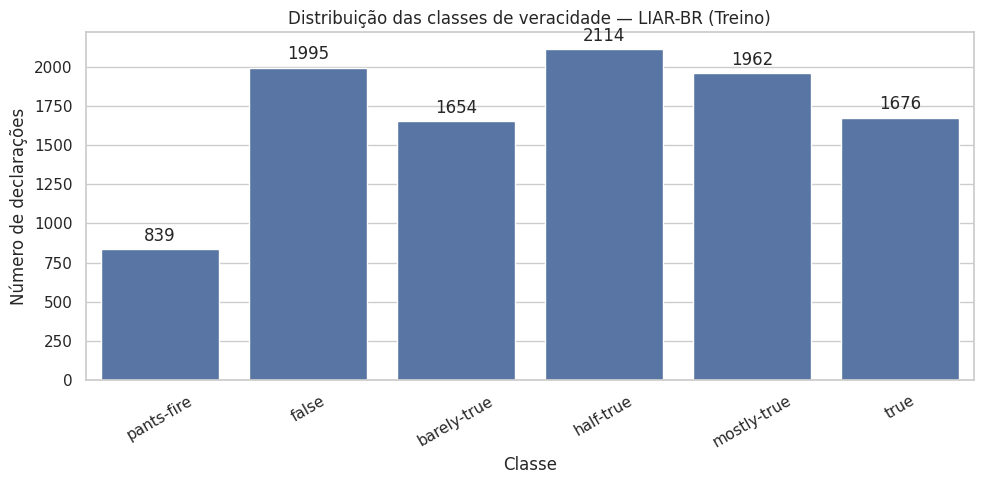

In [ ]:
ordem_classes = [
    "pants-fire",
    "false",
    "barely-true",
    "half-true",
    "mostly-true",
    "true"
]

plt.figure(figsize=(10, 5))

ax = sns.countplot(
    data=train,
    x="label",
    order=ordem_classes
)

plt.title("Distribuição das classes de veracidade — LIAR-BR (Treino)")
plt.xlabel("Classe")
plt.ylabel("Número de declarações")
plt.xticks(rotation=30)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

### 5.2 Distribuição das classes entre treino, validação e teste

Após analisar a distribuição das classes no conjunto de treino, será verificada a composição da variável `label` nas três partições do LIAR-BR.

Como os conjuntos possuem tamanhos diferentes, a comparação será realizada utilizando as **proporções percentuais** de cada classe. Dessa forma, é possível verificar se treino, validação e teste apresentam distribuições semelhantes ou se determinadas categorias possuem diferenças de representação entre as partições.

In [ ]:
ordem_classes = [
    "pants-fire",
    "false",
    "barely-true",
    "half-true",
    "mostly-true",
    "true"
]

def distribuicao_percentual(df):
    return (
        df["label"]
        .value_counts(normalize=True)
        .mul(100)
        .reindex(ordem_classes)
        .round(2)
    )

comparacao_classes = pd.DataFrame({
    "Treino (%)": distribuicao_percentual(train),
    "Validação (%)": distribuicao_percentual(valid),
    "Teste (%)": distribuicao_percentual(test)
})

comparacao_classes.index.name = "Classe"

display(comparacao_classes)

,Treino (%),Validação (%),Teste (%)
Classe,,,
pants-fire,8.19,9.03,7.26
false,19.48,20.48,19.65
barely-true,16.15,18.46,16.73
half-true,20.64,19.31,20.92
mostly-true,19.16,19.55,19.02
true,16.37,13.16,16.42


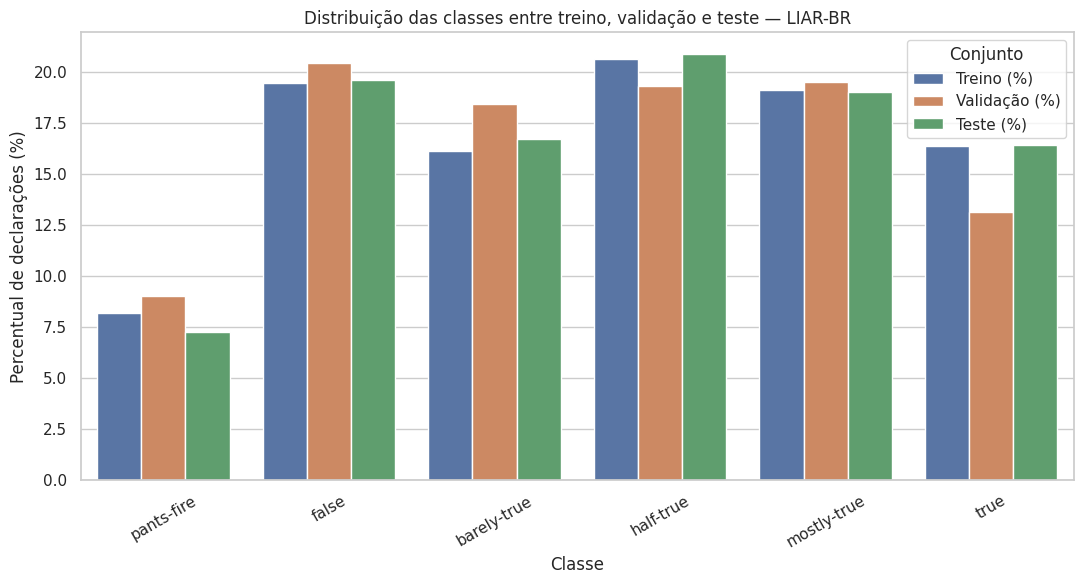

In [ ]:
comparacao_plot = (
    comparacao_classes
    .reset_index()
    .melt(
        id_vars="Classe",
        var_name="Conjunto",
        value_name="Percentual"
    )
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=comparacao_plot,
    x="Classe",
    y="Percentual",
    hue="Conjunto",
    order=ordem_classes
)

plt.title("Distribuição das classes entre treino, validação e teste — LIAR-BR")
plt.xlabel("Classe")
plt.ylabel("Percentual de declarações (%)")
plt.xticks(rotation=30)
plt.legend(title="Conjunto")

plt.tight_layout()
plt.show()

### Resultado da comparação entre os conjuntos

A comparação mostra que a distribuição das classes permanece relativamente semelhante entre os conjuntos de treino, validação e teste.

As classes `false`, `half-true` e `mostly-true` apresentam proporções próximas nas três partições. A classe `pants-fire` permanece como a menos representada, correspondendo a **8,19%** do treino, **9,03%** da validação e **7,26%** do teste.

As maiores diferenças são observadas no conjunto de validação. A classe `barely-true` representa **18,46%** da validação, em comparação com **16,15%** no treino e **16,73%** no teste. Já a classe `true` apresenta menor participação na validação (**13,16%**) do que no treino (**16,37%**) e no teste (**16,42%**).

De maneira geral, não são observadas alterações acentuadas na composição das classes entre as três partições. Entretanto, essas diferenças devem ser consideradas posteriormente na interpretação das métricas de validação e teste.

## 6. Análise das características textuais

### 6.1 Comprimento das declarações

In [ ]:
train_eda = train.copy()

train_eda["num_caracteres"] = (
    train_eda["statement"]
    .astype(str)
    .str.len()
)

train_eda["num_palavras"] = (
    train_eda["statement"]
    .astype(str)
    .str.split()
    .str.len()
)

train_eda[
    ["statement", "num_caracteres", "num_palavras"]
].head()

,statement,num_caracteres,num_palavras
0,O grupo político Annies List defende abortos no terceiro trimestre sob demanda.,79,12
1,"Quando o declínio do carvão começou? Isso começou quando o gás natural ganhou força, o que começou durante a administração de (Presidente George W.) Bush.",154,25
2,"Hillary Clinton concorda com John McCain em ""votar para dar George Bush o benefício da dúvida em relação ao Irã"".",113,20
3,É provável que a legislação de reforma do sistema de saúde exija cirurgias de redesignação sexual gratuitas.,108,17
4,A retomada econômica começou no final do meu mandato.,53,9


### 6.2 Estatísticas descritivas do comprimento das declarações

Após a criação das métricas textuais, serão analisadas estatísticas descritivas do número de caracteres e de palavras das declarações.

Serão observados valores como média, mediana, desvio-padrão, quartis, mínimo e máximo. Essas medidas permitem compreender o tamanho típico das declarações, sua variabilidade e a possível existência de textos com comprimentos muito diferentes do restante do conjunto.

In [ ]:
estatisticas_texto = train_eda[
    ["num_caracteres", "num_palavras"]
].describe().T

estatisticas_texto["mediana"] = train_eda[
    ["num_caracteres", "num_palavras"]
].median()

estatisticas_texto = estatisticas_texto[
    ["count", "mean", "mediana", "std", "min", "25%", "50%", "75%", "max"]
].round(2)

display(estatisticas_texto)

,count,mean,mediana,std,min,25%,50%,75%,max
num_caracteres,10240.0,118.81,110.0,58.89,11.0,81.0,110.0,148.0,2724.0
num_palavras,10240.0,19.67,18.0,9.53,2.0,14.0,18.0,24.0,429.0


### Resultado das estatísticas descritivas

As declarações do conjunto de treino apresentam, em média, **118,81 caracteres** e **19,67 palavras**. As medianas são ligeiramente menores, correspondendo a **110 caracteres** e **18 palavras**.

Metade das declarações possui entre **81 e 148 caracteres** e entre **14 e 24 palavras**, considerando o intervalo entre o primeiro e o terceiro quartil.

Os valores máximos, entretanto, são consideravelmente superiores ao restante da distribuição. A maior declaração possui **2.724 caracteres e 429 palavras**, enquanto o terceiro quartil corresponde a apenas 148 caracteres e 24 palavras.

Essa diferença sugere a presença de uma distribuição assimétrica, com algumas declarações substancialmente mais longas que a maioria. Essa característica será investigada visualmente antes de determinar a presença e a extensão de possíveis valores extremos.

### 6.3 Distribuição do comprimento das declarações

Para compreender melhor a distribuição do tamanho dos textos, será analisado o número de palavras por declaração.

O histograma permite observar onde se concentra a maior parte dos textos e verificar visualmente a presença de assimetria ou de declarações com comprimentos muito superiores ao padrão observado no conjunto.

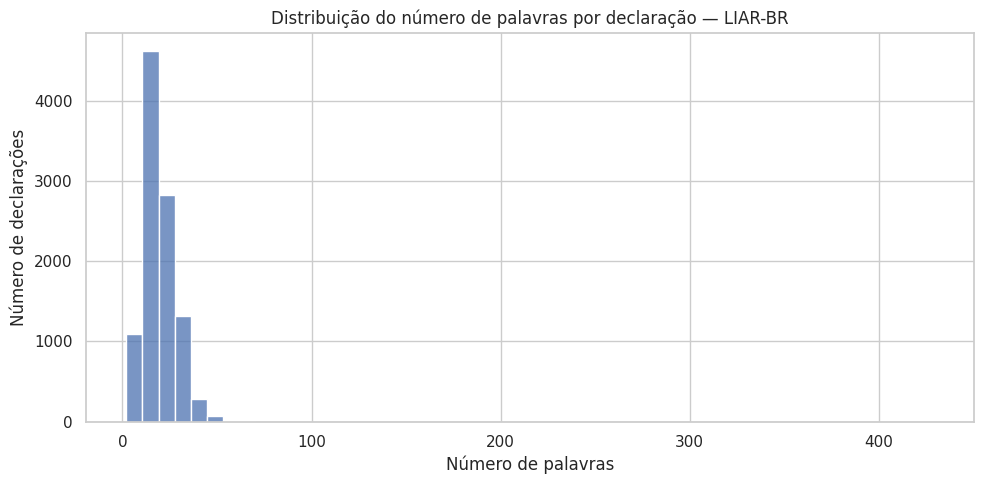

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_eda,
    x="num_palavras",
    bins=50
)

plt.title("Distribuição do número de palavras por declaração — LIAR-BR")
plt.xlabel("Número de palavras")
plt.ylabel("Número de declarações")

plt.tight_layout()
plt.show()

### Resultado da distribuição do comprimento

A distribuição do número de palavras apresenta forte concentração nas declarações mais curtas e uma **cauda longa à direita**.

A maior parte dos registros encontra-se nas faixas inferiores de comprimento, enquanto poucas declarações apresentam quantidade de palavras muito superior ao padrão observado no conjunto.

A presença de uma declaração com até **429 palavras**, em contraste com uma mediana de **18 palavras** e terceiro quartil de **24 palavras**, amplia consideravelmente o eixo horizontal do histograma e comprime visualmente a região onde se concentra a maior parte dos dados.

Esse comportamento reforça a necessidade de investigar separadamente os textos de comprimento extremo antes de decidir se representam erros, casos legítimos ou observações que exigem algum tratamento específico.

### 6.4 Investigação de valores extremos no comprimento das declarações

A distribuição observada sugere a presença de declarações com comprimento muito superior ao padrão do conjunto.

Para investigar esses casos, será utilizado o intervalo interquartil (IQR). Esse critério permite identificar observações que se encontram acima do limite definido por:

**Q3 + 1,5 × IQR**

A identificação desses registros será utilizada apenas para fins exploratórios. Os textos não serão removidos automaticamente, pois valores extremos podem representar observações legítimas do conjunto.

In [ ]:
q1 = train_eda["num_palavras"].quantile(0.25)
q3 = train_eda["num_palavras"].quantile(0.75)

iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

outliers_palavras = train_eda[
    train_eda["num_palavras"] > limite_superior
]

print("=" * 55)
print("ANÁLISE DE VALORES EXTREMOS — NÚMERO DE PALAVRAS")
print("=" * 55)

print(f"Q1: {q1:.0f} palavras")
print(f"Q3: {q3:.0f} palavras")
print(f"IQR: {iqr:.0f} palavras")
print(f"Limite superior: {limite_superior:.1f} palavras")
print(f"Registros acima do limite: {len(outliers_palavras)}")
print(
    f"Percentual do conjunto: "
    f"{len(outliers_palavras) / len(train_eda) * 100:.2f}%"
)

ANÁLISE DE VALORES EXTREMOS — NÚMERO DE PALAVRAS
Q1: 14 palavras
Q3: 24 palavras
IQR: 10 palavras
Limite superior: 39.0 palavras
Registros acima do limite: 228
Percentual do conjunto: 2.23%


### Resultado da identificação de valores extremos

Considerando o número de palavras por declaração, o primeiro quartil (Q1) corresponde a **14 palavras** e o terceiro quartil (Q3) a **24 palavras**, resultando em um intervalo interquartil (IQR) de **10 palavras**.

Pelo critério de 1,5 × IQR, declarações com mais de **39 palavras** são identificadas como valores extremos em relação à distribuição observada.

Foram encontrados **228 registros** acima desse limite, correspondendo a aproximadamente **2,23% do conjunto de treino**.

Esse resultado confirma que a maior parte das declarações possui comprimento relativamente concentrado, enquanto uma pequena parcela apresenta textos substancialmente mais longos. Entretanto, a identificação estatística desses registros como valores extremos não significa que sejam necessariamente erros. Por isso, os casos mais longos serão inspecionados antes de qualquer decisão de tratamento.

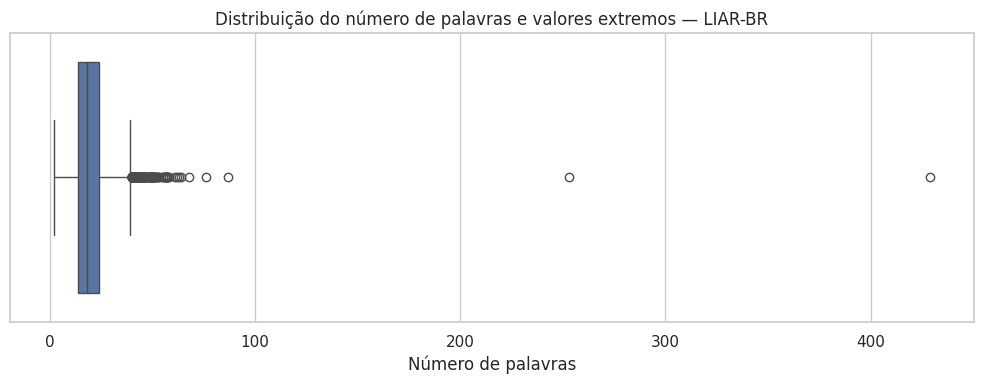

In [ ]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=train_eda,
    x="num_palavras"
)

plt.title("Distribuição do número de palavras e valores extremos — LIAR-BR")
plt.xlabel("Número de palavras")

plt.tight_layout()
plt.show()

In [ ]:
mais_longas = (
    train_eda[
        [
            "statement_ID",
            "statement",
            "label",
            "speaker",
            "num_palavras",
            "num_caracteres"
        ]
    ]
    .sort_values("num_palavras", ascending=False)
    .head(10)
)

display(mais_longas)

,statement_ID,statement,label,speaker,num_palavras,num_caracteres
1280,1606.json,"Hospitais, médicos, ressonâncias magnéticas, cirurgias e assim por diante são mais amplamente utilizados e muito mais caros neste país do que em muitos outros países.\tsaúde-do-cuidado\tmitt-romne...",mostly-true,charlie-crist,429,2724
6119,1993.json,Geórgia tem as leis mais restritivas de acesso aos votos no país.\teleições\tmary-n\t\t\tindependente\t0\t0\t0\t0\t0\tuma entrevista na televisão\n3666.json\tfalso\tSobre se o limite da dívida fed...,true,dan-gelber,253,1716
2142,638.json,"O fato é que, embora tenhamos tido um presidente que se opõe ao aborto nos últimos oito anos, o número de abortos não diminuiu.\taborto\tbarack-obama\tpresidente\tIllinois\tdemocrata\t70\t71\t160\...",false,,87,578
9962,7863.json,"Barbara Buono em números: Como política de Trenton, votou 154 vezes para aumentar os impostos. Sob sua gestão, os impostos sobre propriedades aumentaram 70%. Apoiou um aumento de 16% na taxação so...",mostly-true,republican-governors-association,76,482
427,7176.json,"Atualmente, um dos setores com maior crescimento de empregos é o de Lazer e Hospitalidade. Adicionamos empregos que se concentram principalmente no setor de restaurantes e bares. Estes não são emp...",mostly-true,lou-greenwald,68,417
7271,2987.json,"A Escola Pública de Portland convida funcionários escolares bem pagos e bem alimentados, administradores, professores, outros funcionários, estudantes sem necessidades, pais de estudantes abastado...",barely-true,rees-lloyd,64,466
5026,1540.json,"Ele (Obama) fez várias coisas bem, e a maioria dessas coisas são lugares onde ele mudou de opinião em relação ao que dizia durante a campanha. Por exemplo, ele deixou nossas tropas no Iraque e ela...",false,mitt-romney,63,349
4193,29.json,"Vamos prestar atenção aos jovens que não vão para a faculdade, que são cerca de 60% deles... e treiná-los para os empregos que existem. Porque, sabe, existem empregos de mecânico automotivo que pa...",true,hillary-clinton,62,398
5531,1489.json,"O senador Steve Ogden foi a força motriz por trás da tributação sobre a renda de empresas prejudicar pequenas empresas, elaborou o esquema de financiamento escolar do Robin Hood que fez com que os...",false,ben-bius,61,361
4034,13194.json,"Mike Madigan fez fortuna com recursos contra impostos. Salvou milhões para seus amigos... É um jogo interno jogado por pessoas como Merry Marwig, candidata escolhida por Madigan. Quando Marwig pen...",barely-true,citizens-michael-mcauliffe-and-house-republican-or,58,368


#### Inspeção dos registros extremos

A inspeção das declarações mais longas revelou que os casos mais extremos não parecem corresponder apenas a declarações naturalmente extensas.

O registro com **429 palavras e 2.724 caracteres**, por exemplo, contém no campo `statement` trechos que apresentam a estrutura de outras variáveis do conjunto, incluindo assuntos, emissor, cargo, localização, filiação, contagens históricas e contexto. O mesmo registro também contém novos identificadores terminados em `.json`, seguidos por outras declarações.

Comportamento semelhante foi observado no registro com **253 palavras e 1.716 caracteres**.

Esse padrão sugere a existência de **possíveis anomalias estruturais ou problemas de parsing/formatação em alguns registros**, nos quais informações correspondentes a múltiplos campos ou registros podem ter sido incorporadas ao texto da declaração.

Portanto, os valores extremos identificados não devem ser tratados apenas como declarações longas. Esses casos precisam ser considerados como uma possível questão de qualidade dos dados e investigados antes de qualquer etapa de modelagem ou processamento textual.

In [ ]:
padrao_id_interno = r"\b\d+\.json\b"

suspeitos_estrutura = train_eda[
    train_eda["statement"]
    .astype(str)
    .str.contains(padrao_id_interno, regex=True, na=False)
]

print("=" * 60)
print("POSSÍVEIS ANOMALIAS ESTRUTURAIS")
print("=" * 60)

print(
    f"Declarações contendo outro ID '.json' no texto: "
    f"{len(suspeitos_estrutura)}"
)

print(
    f"Percentual do conjunto: "
    f"{len(suspeitos_estrutura) / len(train_eda) * 100:.4f}%"
)

display(
    suspeitos_estrutura[
        ["statement_ID", "statement", "label", "num_palavras"]
    ]
)

POSSÍVEIS ANOMALIAS ESTRUTURAIS
Declarações contendo outro ID '.json' no texto: 4
Percentual do conjunto: 0.0391%


,statement_ID,statement,label,num_palavras
1280,1606.json,"Hospitais, médicos, ressonâncias magnéticas, cirurgias e assim por diante são mais amplamente utilizados e muito mais caros neste país do que em muitos outros países.\tsaúde-do-cuidado\tmitt-romne...",mostly-true,429
2142,638.json,"O fato é que, embora tenhamos tido um presidente que se opõe ao aborto nos últimos oito anos, o número de abortos não diminuiu.\taborto\tbarack-obama\tpresidente\tIllinois\tdemocrata\t70\t71\t160\...",false,87
6119,1993.json,Geórgia tem as leis mais restritivas de acesso aos votos no país.\teleições\tmary-n\t\t\tindependente\t0\t0\t0\t0\t0\tuma entrevista na televisão\n3666.json\tfalso\tSobre se o limite da dívida fed...,true,253
6173,2007.json,"Quando você estava votando em Republicanos, Brian Kemp estava votando em Democratas.\tmáquina-de-mensagens,registro-de-voto\tdoug-macginnitie\tconselheiro da cidade de Sandy Springs\tGeórgia\trepu...",barely-true,45


#### Resultado da investigação das possíveis anomalias estruturais

A busca por identificadores no formato `.json` dentro do próprio texto das declarações identificou **4 registros**, correspondendo a aproximadamente **0,0391% do conjunto de treino**.

A inspeção desses casos mostra que o campo `statement` contém não apenas o texto da declaração, mas também trechos separados por tabulações que apresentam características das demais variáveis do conjunto, além de novos identificadores de registros.

Esse padrão fornece evidências de possíveis **anomalias de estrutura ou parsing** nesses casos específicos. Dois desses registros também correspondem aos valores mais extremos observados anteriormente, com **429 e 253 palavras**, indicando que parte dos valores extremos de comprimento pode estar associada a problemas estruturais e não apenas a declarações naturalmente extensas.

Entretanto, o fenômeno identificado é pouco frequente no conjunto analisado. Além disso, nem todos os 228 registros classificados como extremos pelo critério do IQR apresentam esse padrão. Portanto, comprimento elevado, isoladamente, não deve ser interpretado como erro.

Os quatro registros suspeitos serão mantidos identificados como uma questão de qualidade dos dados a ser considerada antes de futuras etapas de preparação e modelagem.

### 6.5 Comprimento das declarações por classe de veracidade

Além da distribuição geral do comprimento dos textos, será investigado se as declarações apresentam diferenças de tamanho entre as seis classes de veracidade.

Diferenças sistemáticas entre as classes podem indicar que características superficiais do texto, como seu comprimento, estejam associadas ao rótulo. Em tarefas de classificação textual, esse tipo de padrão merece atenção porque pode ser utilizado pelo modelo como um atalho, sem necessariamente representar características semânticas relacionadas à veracidade da declaração.

Para reduzir a influência das anomalias estruturais identificadas anteriormente, os quatro registros suspeitos serão desconsiderados apenas nesta comparação exploratória, sem alteração do conjunto original.

In [ ]:
ids_suspeitos = suspeitos_estrutura.index

train_texto_valido = train_eda.drop(index=ids_suspeitos).copy()

comprimento_por_classe = (
    train_texto_valido
    .groupby("label")["num_palavras"]
    .agg(
        quantidade="count",
        media="mean",
        mediana="median",
        desvio_padrao="std",
        minimo="min",
        maximo="max"
    )
    .reindex(ordem_classes)
    .round(2)
)

display(comprimento_por_classe)

,quantidade,media,mediana,desvio_padrao,minimo,maximo
label,,,,,,
pants-fire,839,18.87,17.0,7.85,4,48
false,1994,18.42,17.0,8.18,2,63
barely-true,1653,19.92,19.0,8.40,3,64
half-true,2114,20.62,19.5,8.55,2,56
mostly-true,1961,19.95,18.0,8.37,3,76
true,1675,19.36,18.0,7.88,2,62


### Resultado da comparação do comprimento entre as classes

As estatísticas de comprimento mostram que as seis classes apresentam declarações com tamanhos relativamente semelhantes.

As medianas variam entre **17 e 19,5 palavras**, enquanto as médias permanecem entre **18,42 e 20,62 palavras**. A classe `half-true` apresenta a maior média de comprimento (**20,62 palavras**), enquanto `false` apresenta a menor (**18,42 palavras**).

Apesar dessas diferenças, a variação entre as classes é pequena quando comparada à distribuição geral dos textos. Os desvios-padrão também são semelhantes, variando aproximadamente entre **7,85 e 8,55 palavras**.

Descritivamente, portanto, não se observa uma separação acentuada das classes baseada apenas no comprimento das declarações. Esse resultado sugere que o número de palavras, isoladamente, não apresenta um padrão suficientemente distinto entre as categorias para caracterizá-las claramente.

Entretanto, essa análise é exploratória e não permite concluir, por si só, que o comprimento não possua qualquer relação estatística com os rótulos.

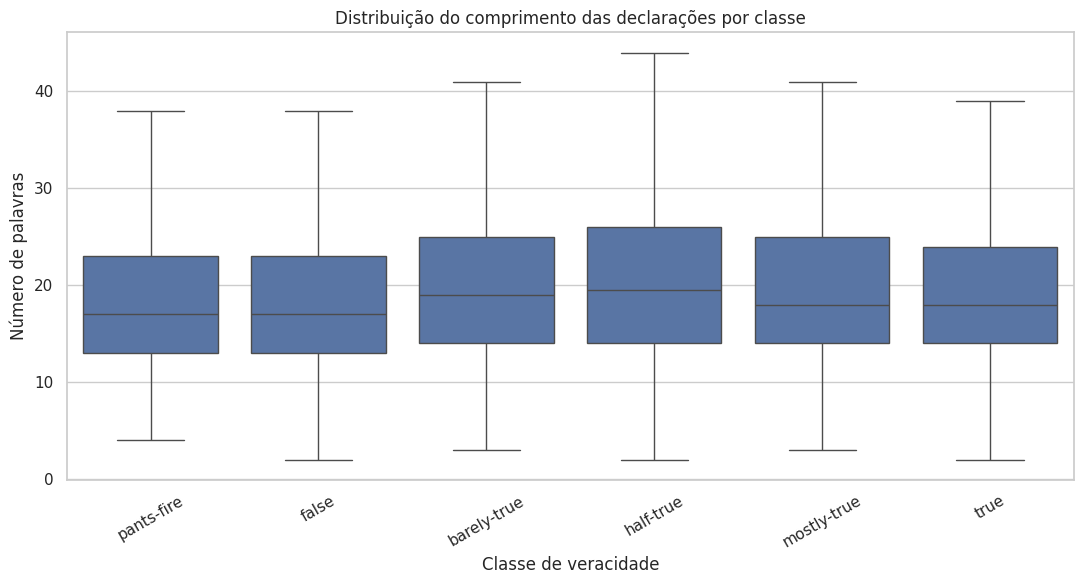

In [ ]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=train_texto_valido,
    x="label",
    y="num_palavras",
    order=ordem_classes,
    showfliers=False
)

plt.title("Distribuição do comprimento das declarações por classe")
plt.xlabel("Classe de veracidade")
plt.ylabel("Número de palavras")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

#### Interpretação do gráfico

O boxplot mostra uma forte sobreposição das distribuições de comprimento entre as seis classes de veracidade. As medianas permanecem próximas e a amplitude das caixas é semelhante entre as categorias.

A classe `half-true` apresenta uma mediana ligeiramente superior, enquanto `pants-fire` e `false` apresentam valores um pouco menores. Entretanto, as diferenças são discretas e não formam grupos claramente separados.

Assim, a visualização reforça o resultado das estatísticas descritivas: **o comprimento das declarações, isoladamente, não apresenta um padrão visual capaz de distinguir claramente as classes de veracidade**.

## 7. Análise lexical das declarações

Após a análise estrutural e do comprimento das declarações, esta etapa explora o conteúdo textual do LIAR-BR.

Em dados de linguagem natural, palavras muito frequentes podem refletir tanto características relevantes do corpus quanto elementos pouco informativos, como artigos, preposições e pontuação. Por isso, será criada uma versão auxiliar dos textos para análise lexical, preservando integralmente a variável `statement` original.

A preparação inicial será utilizada apenas para fins exploratórios e inclui:

- conversão para letras minúsculas;
- remoção de URLs;
- remoção de caracteres não alfabéticos;
- tokenização;
- remoção de stopwords em português.

Algumas palavras potencialmente relevantes para o significado das declarações, especialmente termos de negação como `não`, serão preservadas.

### 7.1 Preparação do texto para análise lexical

In [ ]:
import nltk
import re

from nltk.corpus import stopwords

nltk.download("stopwords")

stopwords_pt = set(stopwords.words("portuguese"))

# Preserva termos de negação que podem alterar o sentido da declaração
for palavra in ["não", "nem"]:
    stopwords_pt.discard(palavra)

print(f"Quantidade de stopwords utilizadas: {len(stopwords_pt)}")

Quantidade de stopwords utilizadas: 205


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
def preparar_texto(texto):
    texto = str(texto).lower()

    # Remove URLs
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)

    # Mantém letras (incluindo caracteres acentuados) e espaços
    texto = re.sub(r"[^a-záàâãéèêíïóôõöúçñ\s]", " ", texto)

    # Tokenização simples
    tokens = texto.split()

    # Remove stopwords, preservando as negações definidas anteriormente
    tokens = [
        palavra for palavra in tokens
        if palavra not in stopwords_pt
    ]

    return " ".join(tokens)


train_texto_valido["statement_preparado"] = (
    train_texto_valido["statement"].apply(preparar_texto)
)

In [ ]:
amostra_textos = train_texto_valido[
    ["statement", "statement_preparado"]
].head(10)

display(amostra_textos)

,statement,statement_preparado
0,O grupo político Annies List defende abortos no terceiro trimestre sob demanda.,grupo político annies list defende abortos terceiro trimestre sob demanda
1,"Quando o declínio do carvão começou? Isso começou quando o gás natural ganhou força, o que começou durante a administração de (Presidente George W.) Bush.",declínio carvão começou começou gás natural ganhou força começou durante administração presidente george w bush
2,"Hillary Clinton concorda com John McCain em ""votar para dar George Bush o benefício da dúvida em relação ao Irã"".",hillary clinton concorda john mccain votar dar george bush benefício dúvida relação irã
3,É provável que a legislação de reforma do sistema de saúde exija cirurgias de redesignação sexual gratuitas.,provável legislação reforma sistema saúde exija cirurgias redesignação sexual gratuitas
4,A retomada econômica começou no final do meu mandato.,retomada econômica começou final mandato
5,Os Chicago Bears tiveram mais quarterbacks titulares nos últimos 10 anos do que o número total de professores de carreira (UW) demitidos nas últimas duas décadas.,chicago bears quarterbacks titulares últimos anos número total professores carreira uw demitidos últimas duas décadas
6,Jim Dunnam não mora no distrito que representa há anos.,jim dunnam não mora distrito representa anos
7,"Sou a única pessoa neste palco que trabalhou ativamente no último ano, juntamente com Russ Feingold, em algumas das reformas éticas mais difíceis desde o Watergate.",única pessoa neste palco trabalhou ativamente último ano juntamente russ feingold algumas reformas éticas difíceis desde watergate
8,"No entanto, foram necessários $19,5 milhões em recursos da Loteria de Oregon para o Porto de Newport finalmente conseguir a nova Unidade de Operações Marítimas da NOAA-Pacífico.",entanto necessários milhões recursos loteria oregon porto newport finalmente conseguir nova unidade operações marítimas noaa pacífico
9,Os oponentes de Glenn Grothman na disputa pela candidatura republicana votaram em um voto de compromisso que custou US$788 milhões em custos mais altos de eletricidade.,oponentes glenn grothman disputa candidatura republicana votaram voto compromisso custou us milhões custos altos eletricidade


#### Verificação de termos de negação

Como listas de stopwords são genéricas, alguns termos removidos automaticamente podem ser relevantes para o contexto das declarações.

Em tarefas de análise de afirmações, palavras de negação podem modificar diretamente o significado de uma frase. Por esse motivo, será verificado se termos como `não`, `nem`, `nunca`, `nada`, `ninguém`, `nenhum` e `nenhuma` fazem parte da lista de stopwords utilizada antes de prosseguir com a análise de frequência.

In [ ]:
termos_negacao = [
    "não", "nem", "nunca", "nada",
    "ninguém", "nenhum", "nenhuma"
]

stopwords_originais = set(stopwords.words("portuguese"))

for termo in termos_negacao:
    print(
        f"{termo}:",
        "é stopword" if termo in stopwords_originais
        else "não é stopword"
    )

não: é stopword
nem: é stopword
nunca: não é stopword
nada: não é stopword
ninguém: não é stopword
nenhum: não é stopword
nenhuma: não é stopword


#### Resultado da verificação

Entre os termos de negação avaliados, apenas `não` e `nem` fazem parte da lista padrão de stopwords em português utilizada pelo NLTK.

Como esses dois termos já haviam sido explicitamente preservados durante a preparação dos textos, não foi necessário realizar novas alterações. Os demais termos avaliados (`nunca`, `nada`, `ninguém`, `nenhum` e `nenhuma`) não fazem parte da lista de stopwords e, portanto, já são naturalmente mantidos.

Essa adaptação evita que a remoção automática de stopwords elimine elementos capazes de modificar o sentido das declarações, mantendo a preparação textual mais adequada ao contexto exploratório do corpus.

### 7.2 Palavras mais frequentes

Após a preparação dos textos, será analisada a frequência dos termos presentes nas declarações.

Essa análise permite caracterizar o vocabulário mais recorrente no LIAR-BR e identificar possíveis temas, entidades ou padrões lexicais presentes no corpus. Também possibilita verificar se, mesmo após a remoção das stopwords, permanecem palavras excessivamente frequentes e pouco informativas.

Inicialmente, serão observadas as 20 palavras mais frequentes no conjunto de treino.

In [ ]:
from collections import Counter

todos_tokens = " ".join(
    train_texto_valido["statement_preparado"]
).split()

frequencia_palavras = Counter(todos_tokens)

top_palavras = pd.DataFrame(
    frequencia_palavras.most_common(20),
    columns=["palavra", "frequencia"]
)

display(top_palavras)

,palavra,frequencia
0,não,1672
1,obama,869
2,anos,759
3,sobre,759
4,diz,754
5,estados,680
6,lei,671
7,saúde,622
8,impostos,609
9,presidente,595


#### Interpretação das palavras mais frequentes

A análise de frequência revela uma presença expressiva de termos associados ao contexto político, econômico e institucional, como `obama`, `presidente`, `lei`, `impostos`, `empregos`, `saúde`, `texas` e `eua`.

O termo `não` é o mais frequente, com **1.672 ocorrências**. Como sua preservação durante a remoção das stopwords foi intencional, esse resultado evidencia a presença recorrente de estruturas de negação nas declarações do corpus.

Também aparecem diferentes formas relacionadas a conceitos semelhantes, como `ano`/`anos` e `estado`/`estados`, além da composição `estados unidos`. Esse resultado mostra uma limitação da contagem de palavras isoladas: variações morfológicas e expressões formadas por mais de uma palavra são contabilizadas separadamente.

O termo `sobre`, com **759 ocorrências**, permanece entre os mais frequentes mesmo após a remoção das stopwords e apresenta baixo valor temático quando analisado isoladamente. Por esse motivo, ele será tratado como uma stopword adicional apenas para as próximas visualizações lexicais.

Por outro lado, termos como `diz` serão inicialmente preservados, pois sua elevada frequência pode refletir características da própria estrutura das declarações e, portanto, constitui um resultado exploratório relevante.

In [ ]:
stopwords_eda = stopwords_pt.copy()
stopwords_eda.add("sobre")

def preparar_texto_eda(texto):
    texto = str(texto).lower()
    texto = re.sub(r"http\S+|www\.\S+", " ", texto)
    texto = re.sub(r"[^a-záàâãéèêíïóôõöúçñ\s]", " ", texto)

    tokens = [
        palavra
        for palavra in texto.split()
        if palavra not in stopwords_eda
    ]

    return " ".join(tokens)

train_texto_valido["statement_lexico"] = (
    train_texto_valido["statement"].apply(preparar_texto_eda)
)

tokens_lexicos = " ".join(
    train_texto_valido["statement_lexico"]
).split()

top_palavras_ajustado = pd.DataFrame(
    Counter(tokens_lexicos).most_common(20),
    columns=["palavra", "frequencia"]
)

display(top_palavras_ajustado)

,palavra,frequencia
0,não,1672
1,obama,869
2,anos,759
3,diz,754
4,estados,680
5,lei,671
6,saúde,622
7,impostos,609
8,presidente,595
9,pessoas,563


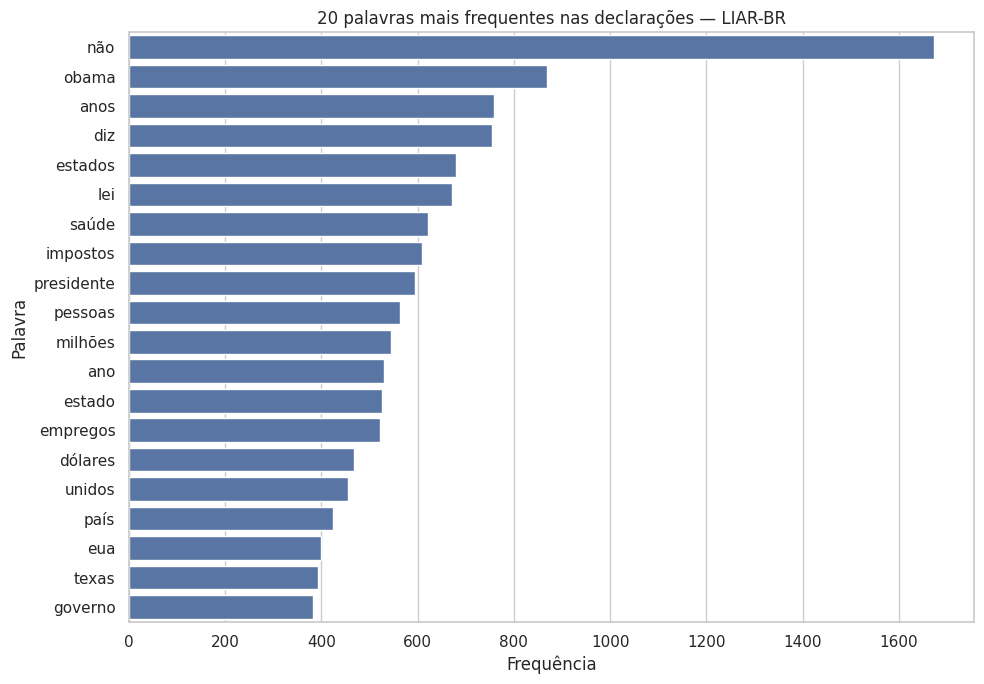

In [ ]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_palavras_ajustado,
    x="frequencia",
    y="palavra"
)

plt.title("20 palavras mais frequentes nas declarações — LIAR-BR")
plt.xlabel("Frequência")
plt.ylabel("Palavra")

plt.tight_layout()
plt.show()

#### Resultado da análise de frequência

A distribuição das palavras mais frequentes reforça a presença de vocabulário relacionado principalmente a temas políticos, econômicos e institucionais. Entre os termos mais recorrentes estão `obama`, `lei`, `saúde`, `impostos`, `presidente`, `empregos`, `governo`, `texas` e `eua`.

A palavra `não` apresenta a maior frequência, com **1.672 ocorrências**, destacando a presença recorrente de estruturas de negação nas declarações. Esse resultado também reforça a importância de sua preservação durante a remoção das stopwords.

A presença separada de termos como `estado` e `estados`, `ano` e `anos`, assim como `estados` e `unidos`, evidencia uma limitação da análise baseada exclusivamente em palavras isoladas. Expressões compostas podem ter significado próprio e não são representadas adequadamente por uma contagem unigramática.

Por esse motivo, a análise seguinte examinará combinações de duas palavras consecutivas (bigramas), buscando identificar expressões recorrentes que complementem a caracterização lexical do corpus.

### 7.3 Bigramas mais frequentes

A análise de palavras isoladas não captura expressões compostas cujo significado depende da combinação entre dois termos. Um exemplo observado anteriormente é `estados unidos`, cujas palavras aparecem separadamente na contagem de frequência.

Para complementar a caracterização lexical do LIAR-BR, serão analisados os bigramas mais frequentes, isto é, pares de palavras consecutivas presentes nas declarações preparadas.

In [ ]:
from nltk.util import bigrams

lista_bigramas = []

for texto in train_texto_valido["statement_lexico"]:
    tokens = texto.split()
    lista_bigramas.extend(bigrams(tokens))

frequencia_bigramas = Counter(lista_bigramas)

top_bigramas = pd.DataFrame(
    [
        (" ".join(bigrama), frequencia)
        for bigrama, frequencia
        in frequencia_bigramas.most_common(20)
    ],
    columns=["bigrama", "frequencia"]
)

display(top_bigramas)

,bigrama,frequencia
0,estados unidos,453
1,barack obama,354
2,hillary clinton,196
3,projeto lei,182
4,presidente obama,150
5,presidente barack,148
6,donald trump,137
7,scott walker,126
8,bilhões dólares,123
9,mitt romney,121


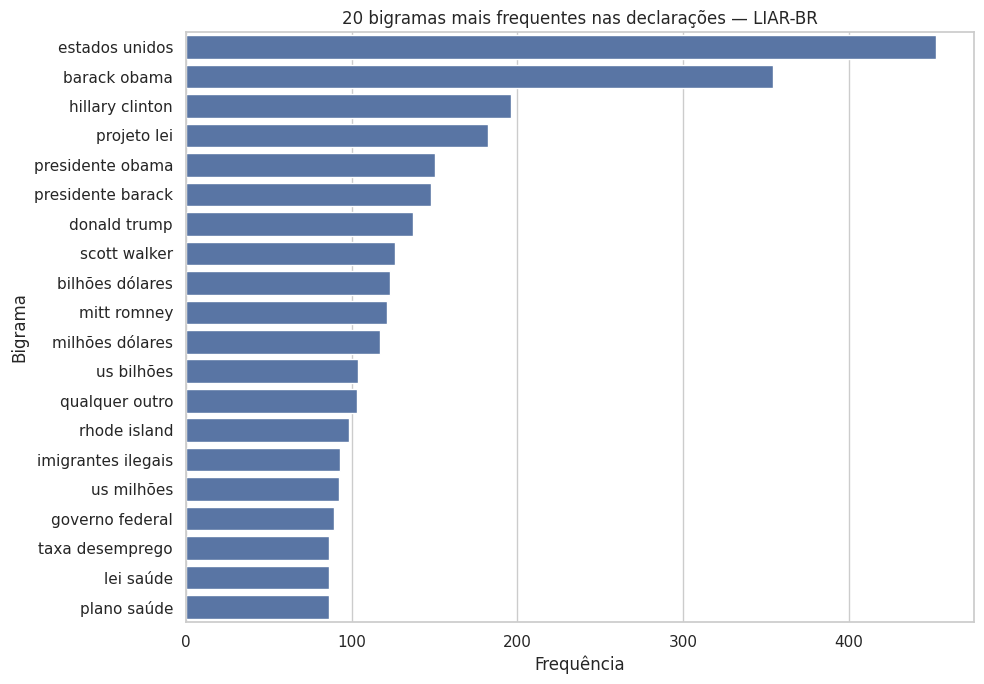

In [ ]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_bigramas,
    x="frequencia",
    y="bigrama"
)

plt.title("20 bigramas mais frequentes nas declarações — LIAR-BR")
plt.xlabel("Frequência")
plt.ylabel("Bigrama")

plt.tight_layout()
plt.show()

## 8. Análise exploratória dos metadados

Além do conteúdo textual, o LIAR-BR disponibiliza metadados associados às declarações, como assunto, emissor, cargo, localização, filiação partidária, contexto e histórico de classificações.

Nesta etapa, serão explorados os metadados mais relevantes para caracterizar a composição do conjunto de dados. O objetivo não é utilizar essas variáveis para realizar predições, mas identificar padrões, concentrações e possíveis limitações do corpus.

### 8.1 Assuntos mais frequentes

A variável `subjects` registra os assuntos associados às declarações. Como uma mesma declaração pode estar relacionada a mais de um assunto, os valores serão separados antes da contagem das frequências.

Essa análise permite identificar quais temas estão mais representados no conjunto de treino e verificar possíveis concentrações temáticas no LIAR-BR.

In [ ]:
subjects_individuais = (
    train_texto_valido["subjects"]
    .dropna()
    .astype(str)
    .str.split(",")
    .explode()
    .str.strip()
)

# Remove valores vazios
subjects_individuais = subjects_individuais[
    subjects_individuais != ""
]

top_subjects = (
    subjects_individuais
    .value_counts()
    .head(20)
    .reset_index()
)

top_subjects.columns = ["assunto", "frequencia"]

display(top_subjects)

,assunto,frequencia
0,economia,851
1,impostos,654
2,Cuidados de saúde,653
3,empregos,615
4,Educação,475
5,orçamento estadual,452
6,Orçamento federal,372
7,crime,354
8,orçamento federal,351
9,Imigração,344


#### Verificação da padronização dos assuntos

A inspeção inicial da variável `subjects` revelou diferenças de padronização entre categorias semanticamente equivalentes.

Foram encontrados, por exemplo, pares como `economia` e `Economia`, `impostos` e `Impostos`, `educação` e `Educação`, `eleições` e `Eleições`, além de `orçamento federal` e `Orçamento federal`.

Essas diferenças de capitalização fazem com que um mesmo assunto seja contabilizado como categorias distintas, podendo distorcer a análise de frequência.

Por esse motivo, os assuntos serão padronizados para letras minúsculas antes da análise de sua distribuição. Essa transformação será aplicada apenas à variável auxiliar utilizada na EDA, preservando os dados originais.

In [ ]:
subjects_padronizados = (
    subjects_individuais
    .str.lower()
    .str.strip()
)

top_subjects_padronizados = (
    subjects_padronizados
    .value_counts()
    .head(20)
    .reset_index()
)

top_subjects_padronizados.columns = ["assunto", "frequencia"]

display(top_subjects_padronizados)

,assunto,frequencia
0,economia,1162
1,impostos,994
2,orçamento federal,731
3,educação,724
4,cuidados de saúde,701
5,empregos,649
6,orçamento estadual,644
7,eleições,629
8,imigração,532
9,política externa,447


#### Resultado da padronização e distribuição dos assuntos

Após a conversão dos assuntos para letras minúsculas, categorias anteriormente fragmentadas por diferenças de capitalização passaram a ser contabilizadas conjuntamente.

A mudança teve impacto relevante nas frequências observadas. `economia`, por exemplo, passou a apresentar **1.162 ocorrências**, enquanto `impostos` apresentou **994**, `orçamento federal` **731**, `educação` **724** e `cuidados de saúde` **701**.

Os resultados mostram que o LIAR-BR possui maior representação de assuntos relacionados a economia, tributação, orçamento, educação, saúde, emprego e eleições. Também aparecem com frequência temas como imigração, política externa, crime, energia e armas.

Parte desses resultados é consistente com os padrões observados anteriormente na análise lexical, na qual termos relacionados a impostos, saúde, empregos, governo e política também apareceram entre os mais frequentes.

A inspeção demonstra ainda a importância da padronização de variáveis categóricas antes da análise de frequência, pois diferenças apenas de capitalização estavam fragmentando categorias equivalentes e subestimando sua ocorrência.

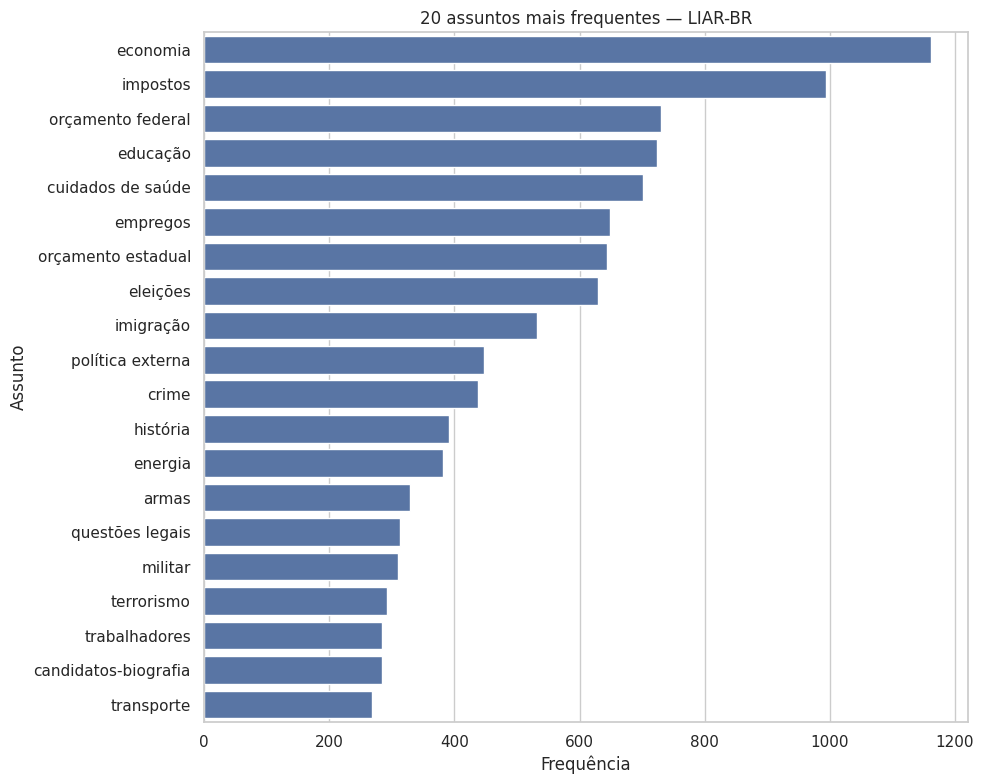

In [ ]:
plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_subjects_padronizados,
    x="frequencia",
    y="assunto"
)

plt.title("20 assuntos mais frequentes — LIAR-BR")
plt.xlabel("Frequência")
plt.ylabel("Assunto")

plt.tight_layout()
plt.show()

### 8.2 Emissores mais frequentes

A variável `speaker` identifica o emissor associado a cada declaração. Sua análise permite verificar se determinados emissores aparecem com maior frequência no conjunto de dados e se existe concentração das observações em um grupo reduzido de indivíduos.

Essa exploração também complementa os resultados da análise lexical, na qual nomes de figuras públicas apareceram entre os bigramas mais frequentes.

Inicialmente, serão observados os emissores mais frequentes conforme registrados originalmente no conjunto de dados, permitindo também identificar possíveis problemas de padronização.

In [ ]:
top_speakers = (
    train_texto_valido["speaker"]
    .astype(str)
    .str.strip()
    .value_counts()
    .head(20)
    .reset_index()
)

top_speakers.columns = ["speaker", "frequencia"]

display(top_speakers)

,speaker,frequencia
0,barack-obama,488
1,donald-trump,273
2,hillary-clinton,239
3,mitt-romney,176
4,scott-walker,149
5,john-mccain,147
6,rick-perry,142
7,chain-email,142
8,marco-rubio,117
9,rick-scott,115


#### Resultado da análise dos emissores

A distribuição da variável `speaker` mostra que algumas figuras aparecem com maior frequência no conjunto de treino. `barack-obama` é o valor mais recorrente, com **488 registros**, seguido por `donald-trump` (**273**), `hillary-clinton` (**239**) e `mitt-romney` (**176**).

Esse resultado é consistente com a análise de bigramas, na qual nomes como `barack obama`, `hillary clinton`, `donald trump` e `mitt romney` também apareceram entre as combinações de palavras mais frequentes.

A inspeção também revelou que a variável `speaker` não contém exclusivamente nomes de indivíduos. Valores como `chain-email`, `facebook-posts` e `blog-posting` também aparecem entre os mais frequentes, indicando que essa variável pode representar, em alguns registros, outras formas de origem ou atribuição das declarações.

Além disso, valores como `bernie-s` sugerem a existência de possíveis abreviações, truncamentos ou formas específicas de registro. Esses casos não serão corrigidos automaticamente nesta etapa, pois sua interpretação exigiria verificação adicional da origem dos dados.

Portanto, a variável deve ser interpretada com cautela: embora seja denominada `speaker`, seus valores não correspondem necessariamente apenas a pessoas.

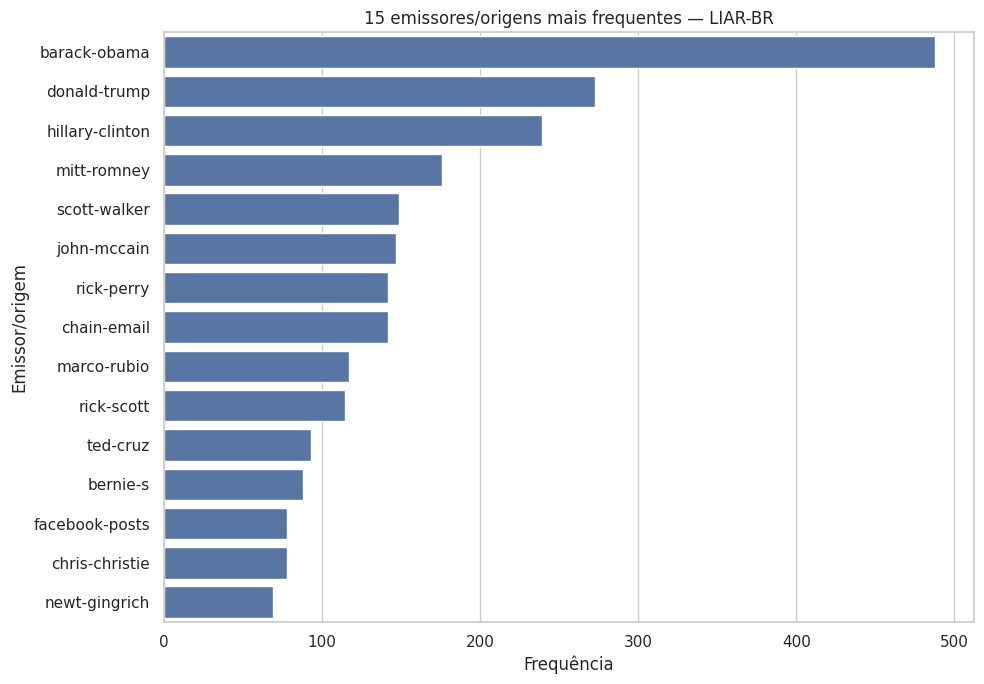

In [ ]:
top_15_speakers = top_speakers.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_15_speakers,
    x="frequencia",
    y="speaker"
)

plt.title("15 emissores/origens mais frequentes — LIAR-BR")
plt.xlabel("Frequência")
plt.ylabel("Emissor/origem")

plt.tight_layout()
plt.show()

## 9. Reconhecimento de Entidades Nomeadas (NER)

Como complemento à análise lexical, será utilizado o Reconhecimento de Entidades Nomeadas (Named Entity Recognition — NER) para explorar quais tipos de entidades aparecem nas declarações do LIAR-BR.

Diferentemente da frequência de palavras e dos bigramas, o NER busca identificar elementos do texto que representam entidades, como pessoas, organizações e localidades.

Nesta EDA, essa técnica será utilizada com finalidade exclusivamente exploratória, buscando caracterizar melhor o conteúdo textual do corpus e verificar quais entidades aparecem com maior recorrência.

In [ ]:
!pip -q install spacy
!python -m spacy download pt_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 46.7 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import spacy

nlp = spacy.load("pt_core_news_sm")

print("Modelo carregado com sucesso.")
print("Pipeline:", nlp.pipe_names)

Modelo carregado com sucesso.
Pipeline: ['tok2vec', 'morphologizer', 'parser', 'lemmatizer', 'attribute_ruler', 'ner']


### 9.1 Identificação das entidades

O reconhecimento de entidades será aplicado sobre as declarações originais, sem a remoção de stopwords ou pontuação realizada anteriormente para a análise lexical.

Essa escolha preserva a estrutura linguística das frases utilizada pelo modelo de NER para reconhecer e classificar as entidades presentes no texto.

Inicialmente, serão contabilizados os tipos de entidades identificados no conjunto de treino.

In [ ]:
from collections import Counter

textos_ner = train_texto_valido["statement"].astype(str).tolist()

contagem_tipos = Counter()
entidades_extraidas = []

for doc in nlp.pipe(textos_ner, batch_size=64):
    for ent in doc.ents:
        contagem_tipos[ent.label_] += 1

        entidades_extraidas.append({
            "entidade": ent.text.strip(),
            "tipo": ent.label_
        })

tipos_entidades = pd.DataFrame(
    contagem_tipos.items(),
    columns=["tipo", "frequencia"]
).sort_values(
    "frequencia",
    ascending=False
).reset_index(drop=True)

display(tipos_entidades)

,tipo,frequencia
0,LOC,6397
1,PER,4391
2,ORG,1891
3,MISC,1676


#### Distribuição dos tipos de entidades identificadas

O modelo de NER identificou quatro categorias de entidades nas declarações analisadas:

- `LOC` — localidades: **6.397 ocorrências**;
- `PER` — pessoas: **4.391 ocorrências**;
- `ORG` — organizações: **1.891 ocorrências**;
- `MISC` — entidades diversas: **1.676 ocorrências**.

As localidades constituem a categoria com maior número de ocorrências, seguidas pelas entidades classificadas como pessoas.

Esses valores representam **ocorrências de entidades reconhecidas pelo modelo**, e não o número de declarações que possuem cada categoria. Uma declaração pode conter mais de uma entidade e uma mesma entidade pode ocorrer em diferentes declarações.

Como o reconhecimento é realizado automaticamente, a classificação produzida pelo modelo será inspecionada antes de uma interpretação mais detalhada dos resultados.

### 9.2 Entidades mais frequentes por categoria

Para avaliar os resultados do reconhecimento automático e caracterizar melhor o corpus, serão observadas as entidades mais frequentes dentro de cada categoria identificada pelo modelo.

Os nomes das entidades serão convertidos para letras minúsculas apenas para a contagem, evitando que diferenças de capitalização façam a mesma entidade ser contabilizada separadamente.

Além de revelar quais pessoas, localidades e organizações aparecem com maior frequência, essa inspeção permite identificar possíveis erros ou limitações do reconhecimento automático de entidades.

In [ ]:
df_entidades = pd.DataFrame(entidades_extraidas)

# Padronização apenas para a contagem
df_entidades["entidade_padronizada"] = (
    df_entidades["entidade"]
    .str.lower()
    .str.strip()
)

top_entidades_por_tipo = (
    df_entidades
    .groupby(["tipo", "entidade_padronizada"])
    .size()
    .reset_index(name="frequencia")
    .sort_values(
        ["tipo", "frequencia"],
        ascending=[True, False]
    )
    .groupby("tipo")
    .head(10)
)

for tipo in ["PER", "LOC", "ORG", "MISC"]:
    print("=" * 60)
    print(tipo)
    print("=" * 60)

    display(
        top_entidades_por_tipo[
            top_entidades_por_tipo["tipo"] == tipo
        ][["entidade_padronizada", "frequencia"]]
    )

PER


,entidade_padronizada,frequencia
2755,barack obama,344
3224,hillary clinton,191
3054,donald trump,133
3859,scott walker,122
3609,mitt romney,118
3773,rick perry,61
3355,john mccain,59
3775,rick scott,58
3645,obama,55
2863,bush,54


LOC


,entidade_padronizada,frequencia
417,estados unidos,416
1084,texas,334
777,obama,331
427,eua,284
1183,wisconsin,259
455,flórida,244
1135,us$,203
251,congresso,149
486,geórgia,142
786,ohio,113


ORG


,entidade_padronizada,frequencia
2442,obamacare,164
2395,medicare,130
2180,democratas,82
2469,partido republicano,55
2522,republicanos,47
2644,us$,43
2487,planned parenthood,29
2403,milwaukee,28
2267,fbi,25
2464,partido democrata,25


MISC


,entidade_padronizada,frequencia
1936,us$,110
1836,senado,85
1711,presidente,75
1854,senado dos eua,61
1789,republicanos,57
1504,isis,43
1530,lei de cuidados acessíveis,33
1594,mccain,30
1693,planned parenthood,21
1827,segunda guerra mundial,20


#### Avaliação dos resultados do NER

A inspeção das entidades mais frequentes mostra que o reconhecimento automático conseguiu identificar diversas entidades coerentes com suas respectivas categorias, especialmente entre as entidades classificadas como pessoas (`PER`). Entre as mais frequentes aparecem `barack obama`, `hillary clinton`, `donald trump`, `scott walker` e `mitt romney`.

Entretanto, também foram observadas inconsistências na classificação automática. Na categoria de localidades (`LOC`), por exemplo, aparecem entidades geográficas plausíveis, como `estados unidos`, `texas`, `wisconsin`, `flórida`, `geórgia` e `ohio`, mas também termos como `obama`, `us$` e `congresso`, que não representam localidades.

Comportamento semelhante ocorre em outras categorias. Em `ORG` e `MISC`, algumas entidades apresentam classificações discutíveis ou aparecem associadas a diferentes tipos.

Esses resultados mostram que o NER é útil para a exploração inicial do conteúdo do corpus, mas suas classificações não devem ser interpretadas como rótulos perfeitos. Como o reconhecimento foi realizado automaticamente sobre declarações traduzidas para o português e inseridas originalmente em um contexto político dos Estados Unidos, erros de reconhecimento e classificação constituem uma limitação relevante desta análise.

Assim, os resultados do NER serão utilizados como apoio para caracterizar o corpus, e não como uma representação definitiva das entidades presentes nas declarações.

## 10. Síntese dos principais achados da EDA — LIAR-BR

A Análise Exploratória de Dados do LIAR-BR permitiu caracterizar a estrutura do conjunto, avaliar aspectos de qualidade dos dados e identificar padrões relacionados às classes, ao conteúdo textual e aos metadados disponíveis.

### Estrutura e qualidade dos dados

Os arquivos utilizados nesta análise possuem **12.791 registros**, distribuídos entre treino (10.240), validação (1.284) e teste (1.267), com 14 variáveis.

Não foram identificadas linhas completamente duplicadas nem identificadores repetidos no conjunto de treino. Foram encontradas, entretanto, declarações textualmente repetidas, inclusive alguns casos associados a rótulos diferentes.

Não existe sobreposição de identificadores entre treino, validação e teste. Foi observada uma pequena sobreposição textual entre os conjuntos, com quatro declarações compartilhadas entre treino e validação e duas entre treino e teste. Esses casos mantêm o mesmo rótulo, embora possam apresentar diferenças em seus metadados.

A análise de valores ausentes mostrou que parte da ausência de informação está representada por strings vazias. A maior concentração ocorre em `speaker_job_title` e `state_info`, enquanto as variáveis centrais, como `statement`, `label` e `statement_ID`, apresentam elevada completude.

Também foram identificados **quatro registros com possíveis anomalias estruturais**, nos quais o campo `statement` contém elementos que aparentam pertencer a outros campos ou registros. Esses casos representam aproximadamente **0,0391%** do conjunto de treino e incluem alguns dos maiores valores observados para o comprimento das declarações.

### Distribuição das classes

O LIAR-BR utiliza seis categorias de veracidade: `pants-fire`, `false`, `barely-true`, `half-true`, `mostly-true` e `true`.

Cinco classes apresentam frequências relativamente próximas no conjunto de treino, enquanto `pants-fire` possui menor representação, correspondendo a aproximadamente **8,19%** dos registros.

As distribuições observadas nos conjuntos de treino, validação e teste são relativamente semelhantes, embora existam pequenas diferenças nas proporções de algumas categorias.

### Características das declarações

As declarações são predominantemente curtas. No conjunto de treino, a mediana é de aproximadamente **18 palavras**, enquanto a média é de **19,67 palavras**.

A distribuição apresenta assimetria à direita, com uma pequena quantidade de textos consideravelmente mais longos. Pelo critério do intervalo interquartil (IQR), **228 registros (2,23%)** foram identificados como valores extremos de comprimento. A inspeção mostrou, porém, que comprimento elevado não representa necessariamente erro, embora alguns dos casos mais extremos estejam associados às anomalias estruturais identificadas.

A comparação entre as classes mostrou medianas entre **17 e 19,5 palavras** e médias entre **18,42 e 20,62 palavras**. As distribuições apresentam forte sobreposição, não sendo observada uma separação visual acentuada das classes baseada apenas no comprimento das declarações.

### Características lexicais

Após uma preparação textual voltada exclusivamente à exploração lexical, foram analisadas as palavras e os bigramas mais frequentes.

A palavra `não` apresentou a maior frequência, com **1.672 ocorrências**, evidenciando a presença recorrente de estruturas de negação no corpus e justificando sua preservação durante a remoção das stopwords.

Também aparecem com frequência termos associados a política, economia e instituições, como `obama`, `lei`, `saúde`, `impostos`, `presidente`, `empregos`, `eua`, `texas` e `governo`.

A análise de bigramas complementou esses resultados, destacando expressões como `estados unidos`, `barack obama`, `hillary clinton`, `projeto lei`, `donald trump`, `bilhões dólares`, `governo federal`, `taxa desemprego` e `plano saúde`.

### Assuntos e emissores

A análise da variável `subjects` revelou inicialmente problemas de padronização relacionados ao uso de letras maiúsculas e minúsculas. Após a normalização, `economia` apareceu como o assunto mais frequente, seguido por `impostos`, `orçamento federal`, `educação`, `cuidados de saúde`, `empregos`, `orçamento estadual` e `eleições`.

Como uma declaração pode possuir mais de um assunto, essas frequências não representam categorias mutuamente exclusivas.

A variável `speaker` também apresentou uma característica relevante: embora contenha predominantemente nomes de indivíduos, inclui valores como `chain-email`, `facebook-posts` e `blog-posting`. Dessa forma, sua interpretação deve considerar que ela pode representar outras formas de origem ou atribuição das declarações, e não exclusivamente pessoas.

### Reconhecimento de entidades

A exploração com Reconhecimento de Entidades Nomeadas (NER) identificou ocorrências classificadas como localidades (`LOC`), pessoas (`PER`), organizações (`ORG`) e entidades diversas (`MISC`).

A inspeção mostrou resultados coerentes principalmente para nomes de pessoas, mas também revelou erros e ambiguidades na classificação automática. Termos como `obama`, `us$` e `congresso`, por exemplo, foram encontrados entre entidades classificadas como localidades.

Portanto, o NER mostrou-se útil como ferramenta exploratória, mas seus resultados devem ser interpretados considerando as limitações do reconhecimento automático.

### Limitações e pontos de atenção

A EDA identificou alguns aspectos que devem ser considerados nas próximas etapas do projeto:

- presença de valores ausentes codificados como strings vazias em algumas variáveis de metadados;
- pequena quantidade de possíveis anomalias estruturais no campo textual;
- existência de declarações textualmente repetidas e pequena sobreposição textual entre diferentes partições do dataset;
- diferenças de padronização em variáveis categóricas;
- menor representação da classe `pants-fire`;
- presença de múltiplos assuntos por declaração;
- heterogeneidade da variável `speaker`;
- erros e ambiguidades produzidos pelo reconhecimento automático de entidades.

De forma geral, o LIAR-BR apresenta uma estrutura rica para exploração de declarações e metadados, mas a EDA mostra que algumas características exigem tratamento e validação cuidadosos antes de etapas posteriores do projeto.

Os resultados desta análise também fornecem uma base para a comparação com os demais conjuntos de dados avaliados pelo grupo, permitindo investigar diferenças de estrutura, conteúdo, rótulos, evidências e qualidade dos dados relevantes para o desenvolvimento da **FOMO**.